# ARTM multi-h CPM demodulation: finding the transmitted path

**Notebook 3 — high-level Python receiver.** We turn received I/Q back into dibits and explain why the receiver
needs memory. The pulse-bank transmitter you proposed and the earlier multiplier transmitter produce the same
waveform when their tables are equivalent; the receiver cares about that waveform, not which implementation generated it.

We assume **known symbol timing, carrier frequency and phase, amplitude, even/odd alignment, and initial state**.
The channel adds complex white Gaussian noise. Synchronization, RF filtering and a practical acquisition preamble are future work.
This is a coherent full-state sequence detector, not a frequency slicer and not a hardware implementation.

The payload is followed by three **known data symbols** so its final pulses are observed completely.
Those symbols are included in detection but excluded from the payload error count. They do not reset phase or represent zero pulses.

In [1]:
from pathlib import Path
from functools import lru_cache
from itertools import product
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

ALPHABET=np.array([-3,-1,1,3])
SPS=8
Rb=1e6
Rs=Rb/2
Fs=SPS*Rs
OUT=Path('figures/demod'); OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.size':11,'axes.grid':True,'figure.figsize':(11,4)})

## 1. What the receiver must do

The transmitter selects a pulse; the receiver does not know which pulse was selected.
It predicts the possible received waveforms, scores their fit, and keeps the best sequence.
The phase and previous symbols are part of each hypothesis. Even/odd alternates at each dibit just as in the transmitter.

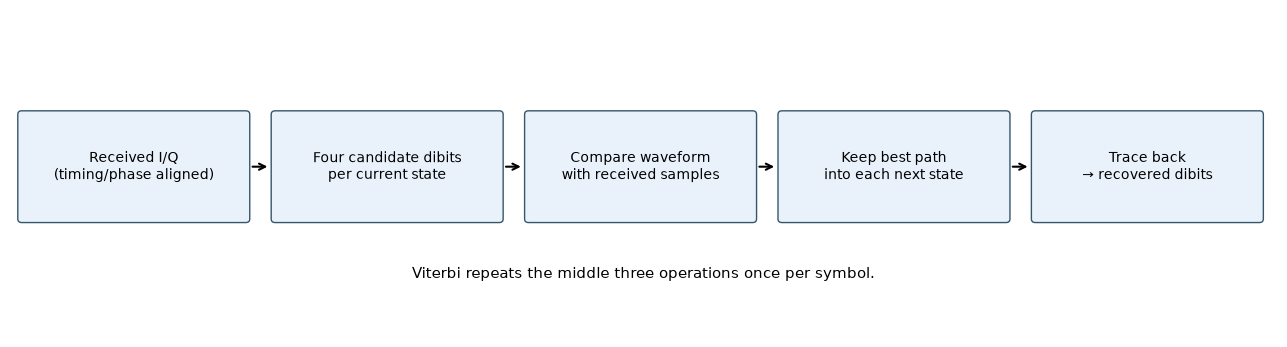

In [2]:
fig,ax=plt.subplots(figsize=(13,3.6)); ax.set(xlim=(0,13),ylim=(0,3.6)); ax.axis('off')
labels=['Received I/Q\n(timing/phase aligned)','Four candidate dibits\nper current state','Compare waveform\nwith received samples','Keep best path\ninto each next state','Trace back\n→ recovered dibits']
for j,label in enumerate(labels):
    x=.12+j*2.6
    ax.add_patch(FancyBboxPatch((x,1.3),2.3,1.15,boxstyle='round,pad=.04',facecolor='#e9f2fb',edgecolor='#36566c'))
    ax.text(x+1.15,1.875,label,ha='center',va='center',fontsize=10)
    if j<4: ax.annotate('',xy=(x+2.55,1.875),xytext=(x+2.34,1.875),arrowprops={'arrowstyle':'->','lw':1.5})
ax.text(6.5,.65,'Viterbi repeats the middle three operations once per symbol.',ha='center')
fig.tight_layout(); fig.savefig(OUT/'01_receiver_chain.png',dpi=150); plt.show()

## 2. Generate a signal, then add noise

We use the same analytic 3-symbol phase pulse as notebook 1. Dibits map to −3, −1, +1, +3;
indices alternate 4/16, 5/16. The receiver is given only the noisy samples and the known trailing symbols.

Noise is controlled by **SNR per complex sample**, $E|s|^2/E|w|^2$, with unit signal power.
This is not a claimed $E_b/N_0$ performance curve. Changing samples/symbol at fixed sample SNR changes the available observation energy.

In [3]:
def phase_pulse(u):
    v = np.clip(np.asarray(u, dtype=float), 0, 3)
    return v/6 - np.sin(2*np.pi*v/3)/(4*np.pi)

def modulate(dibits, sps=8):
    """Independent analytic TX; zero prehistory, first symbol uses h=4/16."""
    a = ALPHABET[np.asarray(dibits, dtype=int)]
    impulses = np.zeros(len(a)*sps)
    impulses[::sps] = a*np.resize([4/16, 5/16], len(a))
    dq = np.diff(phase_pulse(np.arange(3*sps+1)/sps))
    phase = np.r_[0., np.cumsum(np.convolve(impulses,dq))]
    return np.exp(2j*np.pi*phase[:len(impulses)])

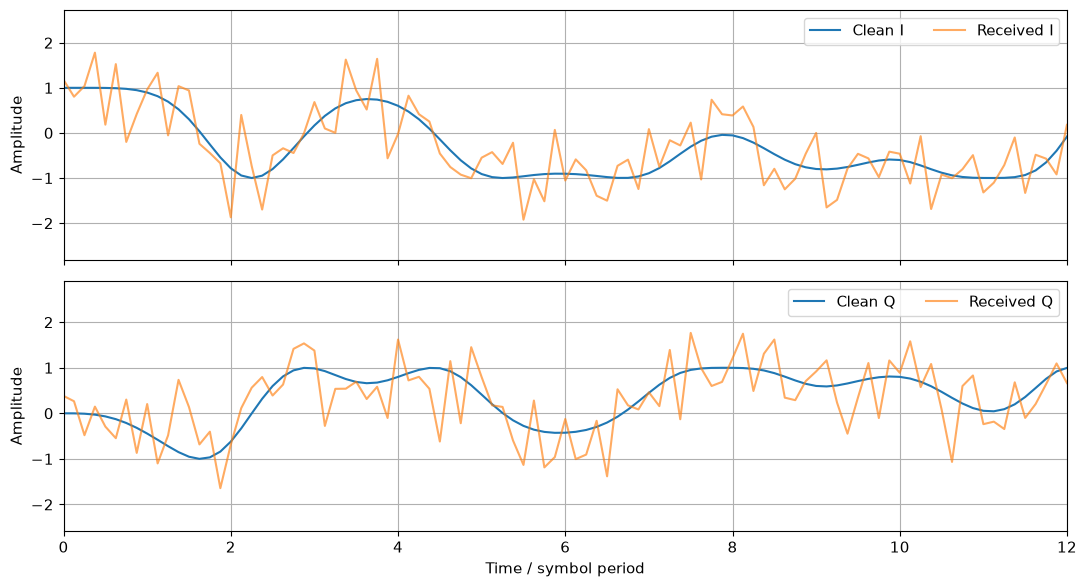

In [4]:
rng=np.random.default_rng(106)
payload=rng.integers(0,4,128)
payload[:8]=[0,0,1,3,2,1,0,3]
tail=np.array([0,0,0])
all_dibits=np.r_[payload,tail]
clean=modulate(all_dibits,SPS)
sample_snr_db=2.0
noise_variance=10**(-sample_snr_db/10)
noise=np.sqrt(noise_variance/2)*(rng.normal(size=len(clean))+1j*rng.normal(size=len(clean)))
received=clean+noise
known={len(payload)+j:int(d) for j,d in enumerate(tail)}
xx=np.arange(len(clean))/SPS
fig,ax=plt.subplots(2,1,figsize=(11,6),sharex=True)
ax[0].plot(xx,clean.real,label='Clean I'); ax[0].plot(xx,received.real,alpha=.65,label='Received I')
ax[1].plot(xx,clean.imag,label='Clean Q'); ax[1].plot(xx,received.imag,alpha=.65,label='Received Q')
for aa in ax: aa.set_xlim(0,12); aa.set_ylabel('Amplitude'); aa.legend(ncol=2)
ax[1].set_xlabel('Time / symbol period')
fig.tight_layout(); fig.savefig(OUT/'02_received_iq.png',dpi=150); plt.show()

## 3. Can we recover the black frequency curve first?

An FM discriminator forms $\arg(r[k+1]r^*[k])F_s/(2\pi)$, an estimate of average frequency over a sample interval.
On a clean signal this recovers the black curve closely. Noise makes phase differences noisy and wrapping can cause large errors.
Even with a perfectly recovered curve, **three symbols overlap**, so it is not simply one of four frequency levels.
More advanced frequency-domain/discriminator receivers are possible; a four-level threshold alone does not undo pulse memory.

Our coherent detector below uses the original I/Q, retaining the phase information rather than decoding the plotted discriminator output.

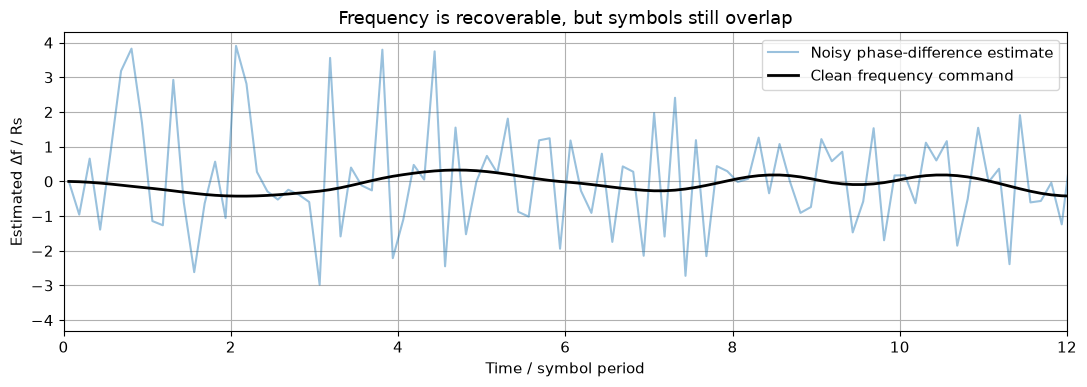

In [5]:
def discriminate(z): return np.angle(z[1:]*np.conj(z[:-1]))*SPS/(2*np.pi)
mid=(np.arange(len(clean)-1)+.5)/SPS
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(mid,discriminate(received),alpha=.45,label='Noisy phase-difference estimate')
ax.plot(mid,discriminate(clean),color='black',lw=2,label='Clean frequency command')
ax.set(xlim=(0,12),xlabel='Time / symbol period',ylabel='Estimated Δf / Rs',title='Frequency is recoverable, but symbols still overlap')
ax.legend(); fig.tight_layout(); fig.savefig(OUT/'03_discriminator.png',dpi=150); plt.show()

## 4. What is a receiver state?

Use a state $(p,b,c)$ at the start of symbol $n$:

- $p/32$ is the accumulated phase **in turns from completed pulses**, modulo one turn.
- $b=a_{n-1}$ and $c=a_{n-2}$ are the two earlier, still-active symbols.
- Even/odd parity is known from $n$, so all hypotheses use the same index schedule.

With $H=4$ for even $n$ and $H=5$ for odd $n$, a candidate $a$ predicts

$$\theta(u)=\frac p{32}+\frac{H a}{16}Q(u)
 +\frac{(9-H)b}{16}Q(u+1)+\frac{Hc}{16}Q(u+2),\quad 0\le u<1.$$

The candidate I/Q is $e^{j2\pi\theta(u)}$. The oldest pulse completes at the next boundary, giving

$$ (p,b,c)\longrightarrow ((p+Hc)\bmod32,\ a,\ b). $$

There are up to $32\times4\times4=512$ state labels. From a known start only a subset may be reachable at a particular time.
At startup we use zero-history sentinels $b=c=0$; zero is not a transmitted data symbol.

Think of an even and an odd **candidate waveform bank**, each indexed by current state and trial dibit.
The receiver tries all four dibits; it cannot select a bank entry using an already-known payload bit.

In [6]:
@lru_cache(maxsize=4096)
def branches(parity, state, sps):
    """state=(completed phase index p, previous symbol b, older symbol c).

    p/32 is phase in turns from fully completed pulses. b,c=0 are startup
    sentinels only; they are not valid data symbols. Even H=4; odd H=5.
    """
    p,b,c = state
    H = 4+parity
    u = np.arange(sps)/sps
    turns = (p/32 + (9-H)*b/16*phase_pulse(u+1)
             + H*c/16*phase_pulse(u+2)
             + H*ALPHABET[:,None]/16*phase_pulse(u))
    templates = np.exp(2j*np.pi*turns)
    next_states = tuple(((p+H*c)%32, int(a), b) for a in ALPHABET)
    return templates, next_states

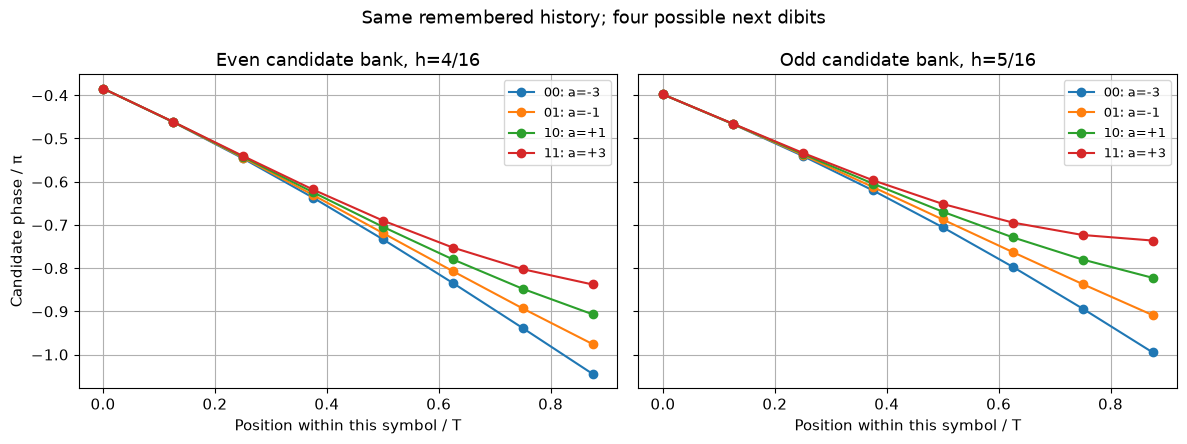

In [7]:
# Illustrate four isolated hypotheses after an agreed history; no future-data knowledge is used.
demo_state=(0,-3,-1)
fig,ax=plt.subplots(1,2,figsize=(12,4.5),sharey=True)
for parity,panel in enumerate(ax):
    templates,_=branches(parity,demo_state,SPS)
    for d in range(4):
        panel.plot(np.arange(SPS)/SPS,np.unwrap(np.angle(templates[d]))/np.pi,'o-',label=f'{d:02b}: a={ALPHABET[d]:+d}')
    panel.set(title=f'{"Even" if parity==0 else "Odd"} candidate bank, h={4+parity}/16',xlabel='Position within this symbol / T')
    panel.legend(fontsize=9)
ax[0].set_ylabel('Candidate phase / π')
fig.suptitle('Same remembered history; four possible next dibits')
fig.tight_layout(); fig.savefig(OUT/'04_candidates.png',dpi=150); plt.show()

## 5. Viterbi: compare, add, select, remember

For each candidate branch, score its distance from the received symbol interval:

$$d=\sum_{m=0}^{N-1}|r[nN+m]-s_{\mathrm{candidate}}[m]|^2.$$

1. Add this branch cost to the cost of the path reaching its starting state.
2. When multiple paths reach the **same complete next state**, keep the lowest-cost one.
3. Save its predecessor and dibit; repeat for the next observation.
4. At the end, choose the lowest-cost final state and trace backward to recover the sequence.

We keep one survivor **per state**, not just one globally best path. Histories reaching the same state have identical
possible futures, so the more expensive one cannot win later under this model. Viterbi does not force the transmitter's phase to be continuous;
it searches waveforms that already obey the continuous-phase model.

This implementation uses full-block traceback for clarity. Streaming receivers typically use a finite traceback delay.

In [8]:
def viterbi(received, sps=8, known=None):
    """Minimum squared-IQ-distance sequence, with full-block traceback.

    known maps symbol positions to known dibits (e.g. a trailing pilot).
    No payload bits enter the detector. AWGN variance is common to all paths,
    so the common likelihood scale can be omitted from the metric.
    """
    y = np.asarray(received).reshape(-1,sps)
    known = {} if known is None else known
    metrics = {(0,0,0): 0.}
    survivors, counts, phase_metrics = [], [], []
    for n, observation in enumerate(y):
        candidates = [int(known[n])] if n in known else range(4)
        updated, links = {}, {}
        for state, cost in metrics.items():
            templates, destinations = branches(n%2, state, sps)
            distances = np.sum(np.abs(templates-observation[None,:])**2,axis=1)
            for d in candidates:
                destination = destinations[d]
                proposed = cost+float(distances[d])
                if proposed < updated.get(destination,np.inf):
                    updated[destination] = proposed
                    links[destination] = (state,d)
        metrics = updated
        survivors.append(links)
        counts.append(len(metrics))
        row = np.full(32,np.inf)
        for (p,b,c), cost in metrics.items(): row[p] = min(row[p],cost)
        phase_metrics.append(row-min(metrics.values()))
    best_state = min(metrics,key=metrics.get)
    best_cost = metrics[best_state]
    decoded = np.empty(len(y),dtype=int)
    state_path = [best_state]
    for n in range(len(y)-1,-1,-1):
        best_state,decoded[n] = survivors[n][best_state]
        state_path.append(best_state)
    return decoded, {'cost':best_cost, 'states':np.array(counts),
                     'phase_metrics':np.array(phase_metrics),
                     'path':list(reversed(state_path))}

def bit_errors(actual, decoded):
    a=np.asarray(actual); b=np.asarray(decoded)
    return int(np.sum((a>>1)!=(b>>1))+np.sum((a&1)!=(b&1)))

Payload: 256 bits; bit errors: 0; observed BER: 0
Maximum reachable states in this run: 256
This is one short noise realization, not a BER benchmark.


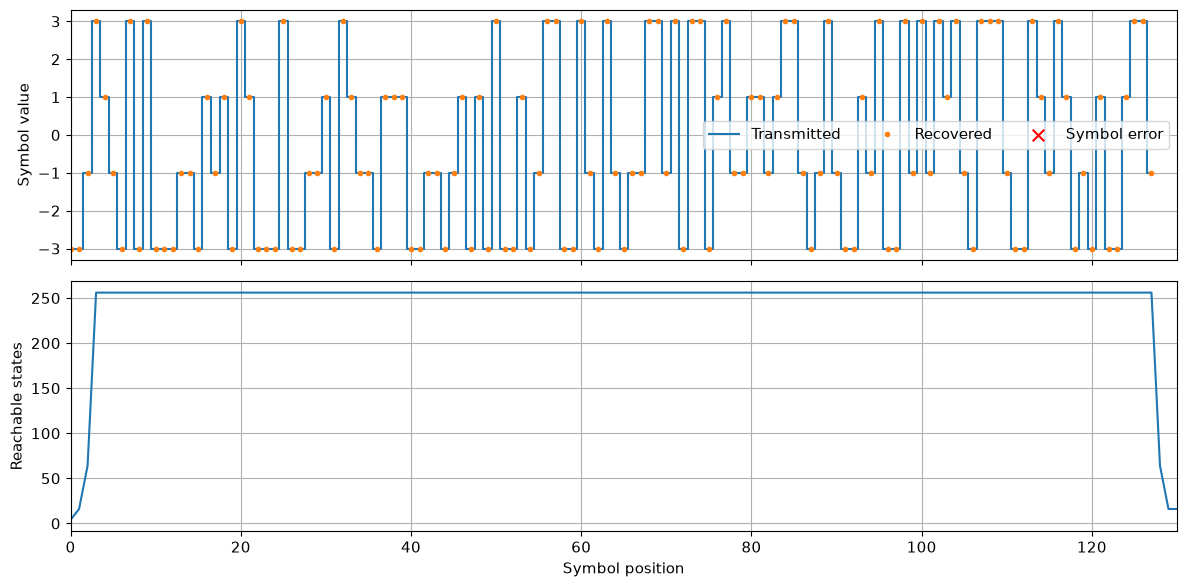

In [9]:
decoded,info=viterbi(received,SPS,known)
recovered=decoded[:len(payload)]
errors=bit_errors(payload,recovered)
print(f'Payload: {2*len(payload)} bits; bit errors: {errors}; observed BER: {errors/(2*len(payload)):.4g}')
print(f'Maximum reachable states in this run: {info["states"].max()}')
print('This is one short noise realization, not a BER benchmark.')
fig,ax=plt.subplots(2,1,figsize=(12,6),sharex=True)
ax[0].step(np.arange(len(payload)),ALPHABET[payload],where='mid',label='Transmitted')
ax[0].plot(np.arange(len(payload)),ALPHABET[recovered],'.',label='Recovered')
wrong=np.flatnonzero(payload!=recovered)
ax[0].scatter(wrong,ALPHABET[recovered[wrong]],color='red',marker='x',s=70,label='Symbol error',zorder=5)
ax[0].set_ylabel('Symbol value'); ax[0].legend(ncol=3)
ax[1].plot(info['states']); ax[1].set(xlabel='Symbol position',ylabel='Reachable states',xlim=(0,len(payload)+len(tail)-1))
fig.tight_layout(); fig.savefig(OUT/'05_recovered_symbols.png',dpi=150); plt.show()

## 6. Visualize the surviving hypotheses

The heatmap groups states by completed-phase index and shows the lowest cost within each group, relative to the best cost
at that time. It collapses the two remembered symbols for display only; the algorithm keeps those states separate.
The white line is the final traceback's phase-state index. It need not be the cheapest partial path at every earlier time.
Dark cells are competitive; bright cells are more expensive; grey cells are unreachable.

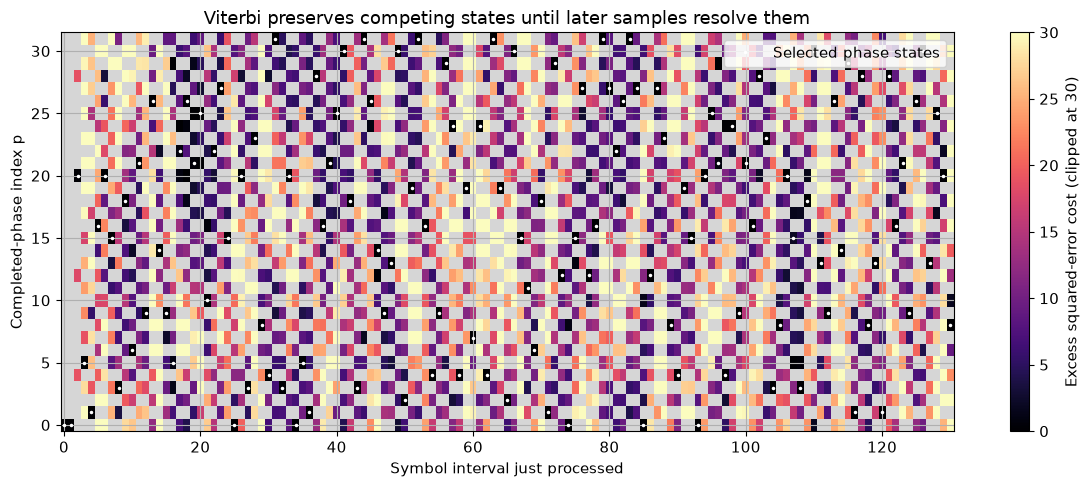

In [10]:
cost_image=np.ma.masked_invalid(info['phase_metrics'].T)
cmap=plt.get_cmap('magma').copy(); cmap.set_bad('#d6d6d6')
fig,ax=plt.subplots(figsize=(12,5))
im=ax.imshow(cost_image,origin='lower',aspect='auto',cmap=cmap,vmin=0,vmax=30,
             extent=(-.5,len(all_dibits)-.5,-.5,31.5),interpolation='nearest')
ax.plot(np.arange(len(all_dibits)),[s[0] for s in info['path'][1:]],'w.',markersize=3,label='Selected phase states')
ax.set(xlabel='Symbol interval just processed',ylabel='Completed-phase index p',title='Viterbi preserves competing states until later samples resolve them')
ax.legend(loc='upper right'); fig.colorbar(im,ax=ax,label='Excess squared-error cost (clipped at 30)')
fig.tight_layout(); fig.savefig(OUT/'06_survivors.png',dpi=150); plt.show()

## 7. Verify that the search really finds the best sequence

First require exact noiseless payload recovery. Then compare Viterbi with an independent exhaustive search of all
256 four-dibit payloads, including the same known tail. They must choose the same sequence and metric.
Finally, compare the transmitter's direct analytic waveform against successive trellis branch templates.
These tests catch state-transition, even/odd and metric mistakes; they do not validate synchronization hardware.

In [11]:
def brute_force(received, payload_length, tail, sps=8):
    """Tiny-block independent exhaustive reference; exponential complexity."""
    candidates = list(product(range(4),repeat=payload_length))
    costs = []
    for candidate in candidates:
        waveform=modulate([*candidate,*tail],sps)
        costs.append(np.sum(np.abs(received-waveform)**2))
    winner=int(np.argmin(costs))
    return np.asarray(candidates[winner]),float(costs[winner])

In [12]:
noiseless,_=viterbi(clean,SPS,known)
assert np.array_equal(noiseless,all_dibits)
state=(0,0,0); reconstructed=[]
for n,d in enumerate(all_dibits):
    templates,destinations=branches(n%2,state,SPS)
    reconstructed.extend(templates[d]); state=destinations[d]
assert np.max(np.abs(np.asarray(reconstructed)-clean)) < 1e-11
tiny_payload=np.array([0,3,1,2]); tiny_tail=np.array([0,0,0])
tiny_clean=modulate(np.r_[tiny_payload,tiny_tail],SPS)
tiny_rng=np.random.default_rng(7)
tiny_rx=tiny_clean+.5*(tiny_rng.normal(size=len(tiny_clean))+1j*tiny_rng.normal(size=len(tiny_clean)))
tiny_known={4+j:int(d) for j,d in enumerate(tiny_tail)}
tiny_v,tiny_info=viterbi(tiny_rx,SPS,tiny_known)
tiny_brute,brute_cost=brute_force(tiny_rx,4,tiny_tail,SPS)
assert np.array_equal(tiny_v[:4],tiny_brute)
assert np.isclose(tiny_info['cost'],brute_cost,rtol=1e-10,atol=1e-10)
print('PASS: noiseless recovery, direct-waveform/trellis agreement, exhaustive-search agreement.')
print(f'Exhaustive-search and Viterbi best metric: {brute_cost:.6f}')

PASS: noiseless recovery, direct-waveform/trellis agreement, exhaustive-search agreement.
Exhaustive-search and Viterbi best metric: 21.943420


## 8. Experiments and the next receiver blocks

Change `sample_snr_db` and rerun to see more or fewer errors. Keep the deterministic seed when comparing changes.
Do not infer a reliable error rate from one short packet; a BER study needs many independent bits and a justified noise normalization.

To build a practical receiver, the next blocks are carrier-frequency/phase acquisition, symbol-timing recovery, even/odd alignment,
and unknown-state initialization. Applying this coherent detector directly to uncorrected carrier offsets will violate its assumptions.
The known trailing symbols here are a teaching boundary condition, not an IRIG framing requirement.

## Source guide

- [Geoghegan, ARTM Tier II waveform](https://www.quasonix.com/files/artm-tier-ii-waveform-itc-paper.pdf): phase-state/trellis description and the demodulator block diagram on PDF pages 4–5. The paper describes a 512-state representation and Viterbi detection.
- [Rice and Perrins, The Detection Efficiency of ARTM CPM in Aeronautical Telemetry](https://scholarsarchive.byu.edu/facpub/392/): author repository record and abstract for reduced-complexity receiver work; this notebook does not reproduce its performance results.
- [RCC 106-20, Chapter 2](https://www.trmc.osd.mil/wiki/download/attachments/240256843/chapter2.pdf?api=v2&modificationDate=1692197849361&version=1): waveform definition and dibit mapping.

The code and illustrations are an educational implementation. No VHDL, FPGA receiver, synchronization loop or calibrated BER claim is included.